# Loading RQs from a file with `goldpan`, and histogramming one

*A first example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-26.*

The RQs (reduced quantities) of a series are the numbers the collaboration's reconstruction computes for every event, stored in a ROOT file (`rqDir/eventTree` for event-level quantities and `rqDir/zip<N>` for the quantities of detector number `N`). `goldpan.adapters.rq_root.read` returns them as one table, one record per event, with the event key first (`series`, `dump`, `event`).

**The data here are made up.** No real RQ file is in the repository. `synthetic-rq/` holds two small ROOT files (24 events in all, about 9 kB each), so that you can see how the reading works on real files on disk. They were written by `python/tests/synthetic_series.py`, which is deterministic (the series name and the channel names imitate Run 76, series `07221203_2025`, but the numbers are random), and the second code cell writes them again if they are missing. To use a real file, only the path and the detector number below change. Needs `uproot` (it is in `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
import sys
from pathlib import Path

import awkward as ak
import matplotlib.pyplot as plt
import numpy as np

from goldpan.adapters import rq_root       # `goldpan` is installed by requirements.txt (pip install -e ./python)

In [2]:
# The synthetic RQ files of this folder (rewritten from the generator if they are missing).
DATA = Path("synthetic-rq")
if not list(DATA.glob("*.root")):
    _here = Path.cwd().resolve()
    REPO = next(p for p in [_here, *_here.parents] if (p / "python" / "tests" / "synthetic_series.py").exists())
    sys.path.insert(0, str(REPO / "python" / "tests"))
    import synthetic_series as ss
    for dump in ss.all_dumps():
        ss.write_rq_root(dump, DATA)
print(sorted(p.name for p in DATA.glob("*.root")))

['07221203_2025_F0001.root', '07221203_2025_F0002.root']


In [3]:
# Read the RQs: a folder of .root files is read file after file. The detector number is never assumed: say it.
table = rq_root.read(DATA, detector=1, branches=["EventType", "PTOFamps", "Side2p*max", "Side2p*maxbin", "Side2p*std"])

print(len(table), "events;", len(ak.fields(table)), "fields")
print(ak.fields(table))
print()
print("the first event:", ak.to_list(table[0]))

24 events; 23 fields
['series', 'dump', 'event', 'EventType', 'PTOFamps', 'Side2pAmax', 'Side2pBmax', 'Side2pCmax', 'Side2pDmax', 'Side2pEmax', 'Side2pFmax', 'Side2pAmaxbin', 'Side2pBmaxbin', 'Side2pCmaxbin', 'Side2pDmaxbin', 'Side2pEmaxbin', 'Side2pFmaxbin', 'Side2pAstd', 'Side2pBstd', 'Side2pCstd', 'Side2pDstd', 'Side2pEstd', 'Side2pFstd']

the first event: {'series': '07221203_2025', 'dump': 'F0001', 'event': 10000, 'EventType': 1, 'PTOFamps': 6.076064646464648e-05, 'Side2pAmax': 12.640232323232322, 'Side2pBmax': 7.801030303030301, 'Side2pCmax': 13.088737373737377, 'Side2pDmax': 11.330232323232323, 'Side2pEmax': 5.829717171717175, 'Side2pFmax': 10.070696969696975, 'Side2pAmaxbin': 1046, 'Side2pBmaxbin': 1042, 'Side2pCmaxbin': 1044, 'Side2pDmaxbin': 1052, 'Side2pEmaxbin': 1053, 'Side2pFmaxbin': 1048, 'Side2pAstd': 2.981841620723076e-08, 'Side2pBstd': 2.983708442490452e-08, 'Side2pCstd': 3.033019825909613e-08, 'Side2pDstd': 3.0064687256898536e-08, 'Side2pEstd': 2.957136220582148e-08, 

Side2pCmax, the pulse height of channel Side2pC above its pretrigger baseline (microamps), events per bin:
       0.1 to      1.3   13
       1.3 to      2.5    0
       2.5 to      3.7    0
       3.7 to      4.9    0
       4.9 to      6.1    1
       6.1 to      7.3    2
       7.3 to      8.5    0
       8.5 to      9.7    3
       9.7 to     10.9    1
      10.9 to     12.1    1
      12.1 to     13.3    2
      13.3 to     14.6    1


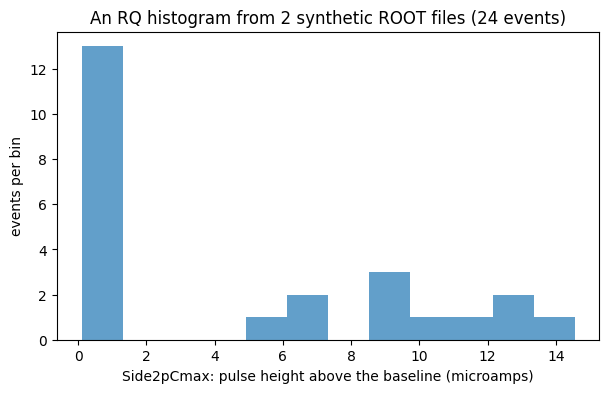

In [4]:
# An RQ histogram: the distribution of one quantity over the events.
def rq_histogram(table, name, bins):
    """Counts and bin edges of the RQ `name` of `table` (NaN, where a detector was not read out, is left out)."""
    values = ak.to_numpy(table[name]).astype(float)
    return np.histogram(values[np.isfinite(values)], bins=bins)


counts, edges = rq_histogram(table, "Side2pCmax", bins=12)
print("Side2pCmax, the pulse height of channel Side2pC above its pretrigger baseline (microamps), events per bin:")
for lo, hi, n in zip(edges[:-1], edges[1:], counts):
    print(f"  {lo:8.1f} to {hi:8.1f}  {n:3d}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.stairs(counts, edges, fill=True, alpha=0.7)
ax.set_xlabel("Side2pCmax: pulse height above the baseline (microamps)")
ax.set_ylabel("events per bin")
ax.set_title(f"An RQ histogram from {len(list(DATA.glob('*.root')))} synthetic ROOT files ({len(table)} events)")
plt.show()

## Bringing up the pulses and plotting the RQs over them

The RQs are numbers about a trace, so the natural check is to draw the trace and mark what the RQ says on it. For that the traces are needed as well: `synthetic-goldpan/` holds the traces of the first synthetic dump (14 events, six sensors, 4096 samples each, about 300 kB) in the native `goldpan` Parquet format, written by the same generator. `goldpan.adapters.read` returns them as an `Events`, and `goldpan.adapters.rq.attach` adds the RQ table to it, matching each event on `series`, `dump` and `event` (event numbers restart in every dump, so all three are needed).

In [5]:
from goldpan import adapters
from goldpan.adapters import rq

# The traces of the first synthetic dump, in the native goldpan format (rewritten from the generator if missing).
TRACES = Path("synthetic-goldpan")
if not TRACES.exists():
    _here = Path.cwd().resolve()
    REPO = next(p for p in [_here, *_here.parents] if (p / "python" / "tests" / "synthetic_series.py").exists())
    sys.path.insert(0, str(REPO / "python" / "tests"))
    import synthetic_series as ss
    ss.write_goldpan(ss.all_dumps()[0], TRACES)

events = adapters.read(TRACES)                  # the format is guessed from the folder
events = rq.attach(events, table)               # the RQs of the same events, joined on series / dump / event

config = events.detector.readout.config()       # the readout of these traces: pretrigger window, glitch samples, sample period
t_us = events.time_axis() * 1e6                 # microseconds from the trigger
print(events)
print("sample period", config.sample_period_s * 1e6, "us; trigger at sample", config.pretrigger_samples)
print("quantities now include", [f for f in ak.fields(events.quantities) if f.startswith("Side2pC")])

Events(detector='NSDF', n_events=14, traces=[('Side2pA', 'main'), ('Side2pB', 'main'), ('Side2pC', 'main'), ('Side2pD', 'main'), ('Side2pE', 'main'), ('Side2pF', 'main')], quantities=['series', 'dump', 'event', 'trigger_type', 't_trigger', 'EventType', 'PTOFamps', 'Side2pAmax', 'Side2pBmax', 'Side2pCmax', 'Side2pDmax', 'Side2pEmax', 'Side2pFmax', 'Side2pAmaxbin', 'Side2pBmaxbin', 'Side2pCmaxbin', 'Side2pDmaxbin', 'Side2pEmaxbin', 'Side2pFmaxbin', 'Side2pAstd', 'Side2pBstd', 'Side2pCstd', 'Side2pDstd', 'Side2pEstd', 'Side2pFstd'])
sample period 0.7999999999999999 us; trigger at sample 1000
quantities now include ['Side2pCmax', 'Side2pCmaxbin', 'Side2pCstd']


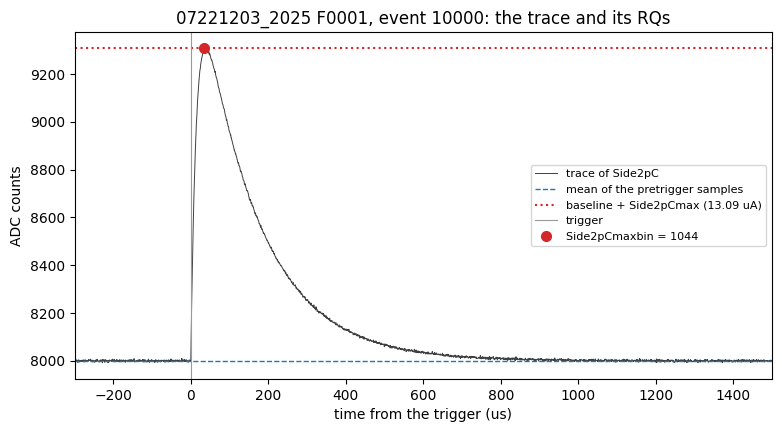

the trace maximum is 9309.0 counts; baseline + RQ is 9309.0


In [6]:
# One channel, the event with the biggest Side2pC pulse, and what its RQs say.
COUNTS_PER_UA = 100        # the synthetic calibration (1e-8 A per count); for real data use the calibration of the readout

name = "Side2pC"
q = events.quantities
i = int(np.argmax(ak.to_numpy(q[name + "max"])))                 # index of the event with the largest pulse in this channel
trace = events.trace(name)[i].astype(float)
pre = trace[config.glitch_samples:config.pretrigger_samples]     # the pretrigger samples, after the glitch
baseline = pre.mean()
peak_level = baseline + float(q[name + "max"][i]) * COUNTS_PER_UA        # baseline plus the RQ "max" (microamps) in counts
maxbin = int(q[name + "maxbin"][i])                                      # the RQ "maxbin": the sample of the maximum

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t_us, trace, lw=0.7, color="0.25", label=f"trace of {name}")
ax.axhline(baseline, color="C0", ls="--", lw=1, label="mean of the pretrigger samples")
ax.axhline(peak_level, color="C3", ls=":", lw=1.5, label=f"baseline + {name}max ({float(q[name + 'max'][i]):.2f} uA)")
ax.axvline(0, color="0.6", lw=0.8, label="trigger")
ax.plot(t_us[maxbin], trace[maxbin], "o", color="C3", ms=7, label=f"{name}maxbin = {maxbin}")
ax.set_xlabel("time from the trigger (us)")
ax.set_ylabel("ADC counts")
ax.set_title(f"{q['series'][i]} {q['dump'][i]}, event {q['event'][i]}: the trace and its RQs")
ax.set_xlim(-300, 1500)
ax.legend(fontsize=8, loc="center right")
plt.show()
print("the trace maximum is", trace.max(), "counts; baseline + RQ is", round(peak_level, 1))

The line at *baseline + `Side2pCmax`* lands on the top of the pulse, and the dot sits at `Side2pCmaxbin`: the RQs are a short description of the trace. In the synthetic files the RQ `max` is in microamps and the conversion is a made-up 100 counts per microamp, so it is written in the cell above; for a real file the conversion comes from the readout (see the note on normalizing the pulses to QET current).

The same for all six sensors of the event at once:

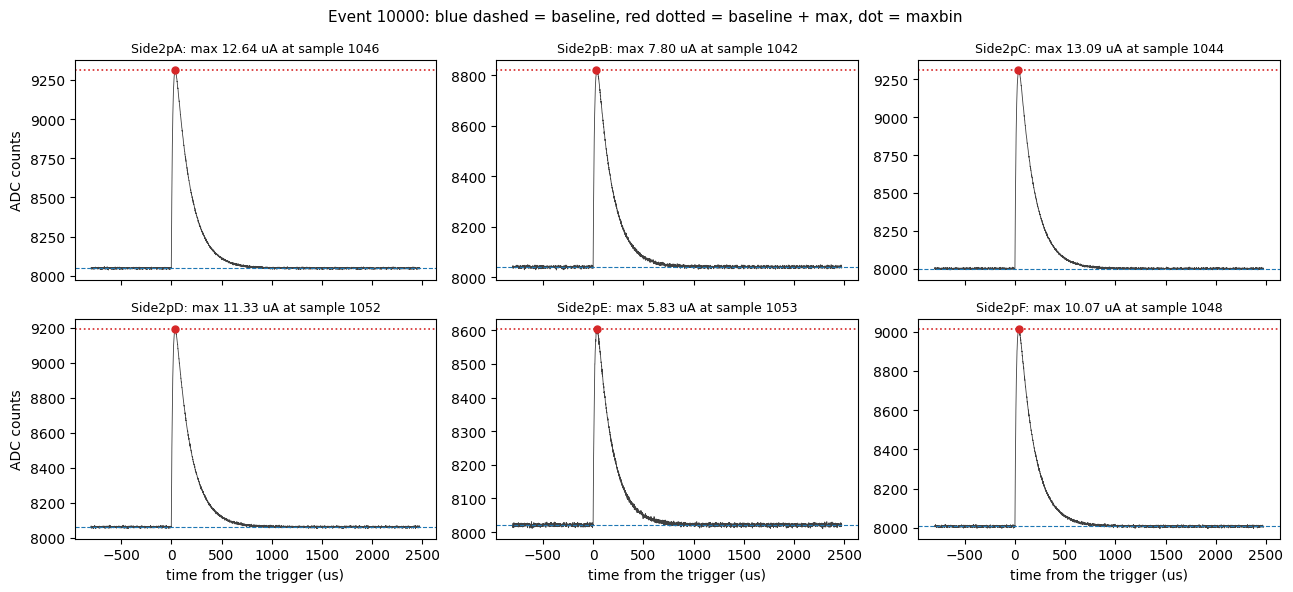

In [7]:
# All six sensors of the same event, each with its own RQs.
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, ch in zip(axes.flat, sorted(events.detector.channel_names())):
    tr = events.trace(ch)[i].astype(float)
    base = tr[config.glitch_samples:config.pretrigger_samples].mean()
    mx, mb = float(q[ch + "max"][i]), int(q[ch + "maxbin"][i])
    ax.plot(t_us, tr, lw=0.6, color="0.25")
    ax.axhline(base, color="C0", ls="--", lw=0.8)
    ax.axhline(base + mx * COUNTS_PER_UA, color="C3", ls=":", lw=1.2)
    ax.plot(t_us[mb], tr[mb], "o", color="C3", ms=5)
    ax.set_title(f"{ch}: max {mx:.2f} uA at sample {mb}", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("time from the trigger (us)")
for ax in axes[:, 0]:
    ax.set_ylabel("ADC counts")
fig.suptitle(f"Event {q['event'][i]}: blue dashed = baseline, red dotted = baseline + max, dot = maxbin", fontsize=11)
fig.tight_layout()
plt.show()

**What this shows, and what is next.** `rq_root.read` gives a table, and a histogram of an RQ is a `numpy` histogram of one of its columns. Not done here: cuts on the RQs (`goldpan.rq_cuts`), and reading the RQs of a real series: the names of the real RQs, and which detector number to ask for, come from the reconstruction of that series.